# X-band radar processing and convective probability

Radar part of *Regime-dependent evolution of water vapor, cloud liquid, and cloud base before rain onset in the southeastern Alpine forelands* 

For every rain event the WegenerNet 3D X-band radar (FURUNO WR2120, Kirchberg an der Raab) is used to decide whether the event is **convective**, whether it has a **hail** signature, and how high the **echo top** reaches. The chain is

| Section | Step | Output |
| --- | --- | --- |
| 1 | settings, example events | — |
| 2 | polar L1b sweeps → 3-D Cartesian grid around the radiometer (wradlib CAPPI) | `Z_h_corr`, `zdr_corr`, `kdp`, `rhohv`, `vradh`, `wradh`, `phidp` on (time, h, y, x) |
| 3 | 0 °C and −5 °C isotherm heights from the microwave-radiometer (MWR) temperature profile | freezing level (melting layer), −5 °C level (rain type) |
| 4 | quality control, convective and hail probability (Fig. 3 of the paper) | `prob_q95_q95`, `prob_hail` per event |
| 5 | echo-top height (Z_h > 0 dBZ) | input of the rain-type classification (Fig. 2) |
| 6 | sensitivity of the classification to weights and threshold | Fig. A1 (`figures/fA01.png`) |
| 7 | example event: Z_h and Z_DR above the radiometer with the −5 °C isotherm | `figures/examples/` |

**What runs by default.** Sections 2–5 and 7 run for **two example events** only:
a convective event (8 June 2023, onset 13:40 UTC) and a non-convective event (16 May 2024, onset 18:50 UTC).
Processing all events (gridding of ~390 event windows, ~40 GB; convective probability of 644 events) is written in functions that are switched off (`RUN_ALL_EVENTS = False`).

**Freezing level.** The melting layer is placed between the 0 °C level of the MWR profile and 500 m above it. The convective probabilities stored in `data/processed/summer_events_with_conv_prob_20260630.nc` 

Input data: see `data/README.md`.

## 1. Settings

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", message="In a future version of xarray the default value for",
                        category=FutureWarning)

# ----- repository folders (the notebook is run from notebooks/) -----
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
RAW_DIR = ROOT / "data" / "raw"                 # WegenerNet data (not in the repository, see data/README.md)
PROCESSED_DIR = ROOT / "data" / "processed"     # small derived files shipped with the repository
DERIVED_DIR = ROOT / "data" / "derived"         # large derived files made by this notebook
FIG_DIR = ROOT / "figures"
(FIG_DIR / "examples").mkdir(parents=True, exist_ok=True)

L1B_DIR = RAW_DIR / "radar_L1b"                                         # WN3D L1b v1 polar sweeps, one file per day
TSR_DIR = RAW_DIR / "WegenerNet_Transfer" / "L2a" / "v2.0-rc1" / "TSR"   # MWR L2a v2.0-rc1 (temperature profiles)
GRID_DIR = DERIVED_DIR / "radar_L1_cartesian"                            # gridded event windows (Section 2)

# GDAL/PROJ (used by wradlib for the projection): take the PROJ database of this Python
# environment; a PROJ_DATA of another installation (e.g. the conda base) breaks the EPSG lookup
proj_dir = Path(sys.prefix) / "share" / "proj"
if (proj_dir / "proj.db").exists():
    os.environ["PROJ_DATA"] = str(proj_dir)

from analysis import find_freezing_level
from event_based_functions import calculate_minus5_isotherm_height
from event_based_plotting import plot_minus5_isotherm
from radar_gridding import build_wrl_gridder, wradlib_area_over_time
import convective_probability as cp
from echo_top import echo_top_height, echo_top_height_files
import sensitivity

from figure_style import FONT_RC, style_fonts
plt.rcParams.update(FONT_RC)         # one font family and set of font sizes for all figures

# ----- site and grid -----
RADIOMETER_XY = (564565.44, 5200868.51)      # microwave radiometer, UTM 33N [m]
GRID_HALF_WIDTH = 3000.0                     # grid box: radiometer +/- 3 km [m]
GRID_SPACING = 200.0                         # horizontal grid spacing [m]
# CAPPI levels [m a.s.l.]: 100 m steps up to 2.8 km, 200 m steps from 3 to 10 km
H_LEVELS = np.r_[np.arange(1000, 2801, 100), np.arange(3000, 10001, 200)]
EVENT_WINDOW = (np.timedelta64(-120, "m"), np.timedelta64(90, "m"))   # gridded window around each rain onset
PROB_HALF_WINDOW = np.timedelta64(30, "m")                             # convective probability: onset +/- 30 min

# ----- example events (rain onset at the superstation, UTC) -----
EXAMPLES = {
    "2023-06-08T13:40": "convective",
    "2024-05-16T18:50": "non-convective",
}
RUN_ALL_EVENTS = False   # True: process every event (hours of computing, ~40 GB of gridded files)

## 2. Polar sweeps → Cartesian grid (wradlib CAPPI)

The L1b files hold the attenuation-corrected reflectivity `Z_h_corr` (dBZ), differential reflectivity `zdr_corr` (dB), specific differential phase `kdp` (° km⁻¹), co-polar correlation coefficient `rhohv`, radial velocity `vradh` and spectrum width `wradh` (m s⁻¹) and the differential phase `phidp` on 10 elevations × 361 azimuths × 101 range gates, every 2.5 min.

Each gate is projected to UTM 33N with the 4/3 effective Earth radius model, and every grid point (200 m × 200 m, 55 levels from 1 to 10 km) gets the inverse-distance-weighted mean of its 4 nearest gates (power 2). Grid points below the lowest or above the highest elevation, or beyond the maximum range, stay empty. The window of every event is onset − 2 h to onset + 1.5 h.

*Note:* the quality-flag names searched by `wradlib_area_over_time` (`ste_prob`, `rad_qcs_flag`, `qcs_flag`, `quality_flag`) do not include the flag of the L1b files (`radar_qcs_flag`), so no gate is removed before gridding. This is how the gridded files used in the paper were made.

In [2]:
def grid_event(onset, l1b_file=None, grid=None):
    """Grid the radar sweeps of one event window (onset - 2 h ... onset + 1.5 h)."""
    onset = np.datetime64(onset)
    l1b_file = l1b_file or L1B_DIR / f"WN3D_L1b_v1_PrecipRadar_Sweeps_{str(onset)[:10]}.nc"
    if grid is None:
        grid = build_wrl_gridder(
            l1b_file,
            x_min=RADIOMETER_XY[0] - GRID_HALF_WIDTH, x_max=RADIOMETER_XY[0] + GRID_HALF_WIDTH,
            y_min=RADIOMETER_XY[1] - GRID_HALF_WIDTH, y_max=RADIOMETER_XY[1] + GRID_HALF_WIDTH,
            dx=GRID_SPACING, dy=GRID_SPACING, h_levels=H_LEVELS, nnearest=4, p=2.0,
        )
    return wradlib_area_over_time(
        l1b_file, grid,
        begin_time=str(onset + EVENT_WINDOW[0]), end_time=str(onset + EVENT_WINDOW[1]),
        chunks_time=16,
    )


def gridded_file_name(onset):
    """File name of a gridded event window, e.g. processedL1_2023-06-08_13-40.nc."""
    t = pd.Timestamp(onset)
    return f"processedL1_{t:%Y-%m-%d_%H-%M}.nc"


radar = {}
for onset in EXAMPLES:
    radar[onset] = grid_event(onset)
    print(f"{onset}: {dict(radar[onset].sizes)}")

    # compare with the gridded file used in the paper, if it is available
    stored_file = GRID_DIR / gridded_file_name(onset)
    if stored_file.exists():
        with xr.open_dataset(stored_file) as stored:
            for var in ["Z_h_corr", "zdr_corr", "kdp", "rhohv"]:
                diff = np.abs(radar[onset][var] - stored[var])
                print(f"    {var:9s} max |new - stored| = {float(diff.max()):.2e}")

/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/src/radar_gridding.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 16. This could degrade performance. Instead, consider rechunking after loading.
  ds_all = xr.open_dataset(l1b_nc, **open_kwargs)


2023-06-08T13:40: {'time': 85, 'h_msl_m': 55, 'y_utm': 31, 'x_utm': 31}
    Z_h_corr  max |new - stored| = 0.00e+00
    zdr_corr  max |new - stored| = 0.00e+00
    kdp       max |new - stored| = 0.00e+00
    rhohv     max |new - stored| = 0.00e+00


/home/esg/PostDoc_WEGN4CARE/LWP_IWV_before_rain/src/radar_gridding.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 16. This could degrade performance. Instead, consider rechunking after loading.
  ds_all = xr.open_dataset(l1b_nc, **open_kwargs)


2024-05-16T18:50: {'time': 85, 'h_msl_m': 55, 'y_utm': 31, 'x_utm': 31}
    Z_h_corr  max |new - stored| = 0.00e+00
    zdr_corr  max |new - stored| = 0.00e+00
    kdp       max |new - stored| = 0.00e+00
    rhohv     max |new - stored| = 0.00e+00


In [3]:
def grid_all_events(event_starts, out_dir=GRID_DIR):
    """Grid every event window and save one file per event (only if RUN_ALL_EVENTS)."""
    out_dir.mkdir(parents=True, exist_ok=True)
    for onset in event_starts:
        out = out_dir / gridded_file_name(onset)
        if out.exists():
            continue
        l1b_file = L1B_DIR / f"WN3D_L1b_v1_PrecipRadar_Sweeps_{pd.Timestamp(onset):%Y-%m-%d}.nc"
        if not l1b_file.exists():
            print(f"no L1b file for {onset}")
            continue
        grid_event(onset, l1b_file).to_netcdf(out)


all_events = xr.open_dataset(PROCESSED_DIR / "all_events.nc").to_dataframe()   # rain events at station 156
warm_season = all_events[(all_events["start"].dt.month >= 4) & (all_events["start"].dt.month <= 9)]
if RUN_ALL_EVENTS:
    grid_all_events(warm_season["start"].values)

## 3. Isotherm heights from the microwave radiometer

The L2a temperature profile `T_profile` (K) of the HATPRO radiometer is given on fixed heights `h_msl` (m a.s.l.) every 2.5 min, with a data-processing flag `T_profile_dpg_flag` (0 = measured).

* **Freezing level (0 °C)** — lowest height where the profile crosses 273.15 K, linearly interpolated between the two levels around the crossing (`analysis.find_freezing_level`). It sets the melting layer of the convective algorithm. If no profile is available within onset ± 30 min, the valid profile nearest to the onset within ± 3 h is used, otherwise 3000 m.
* **−5 °C isotherm** — the grid level with the coldest temperature that is still warmer than −5 °C, with its vertical grid cell as uncertainty band and a quality flag (`event_based_functions.calculate_minus5_isotherm_height`). This is the level drawn in the event figures; the rain-type classification (Fig. 2) uses the interpolated −5 °C crossing.

In [4]:
def load_profiles(onset, days_around=1):
    """MWR temperature profiles of the onset day and the neighbouring days."""
    day = pd.Timestamp(onset).normalize()
    files = [TSR_DIR / f"WN3DO_L2a_v2lrc1_TSR_TroposphericProfiles_{d:%Y-%m-%d}.nc"
             for d in pd.date_range(day - pd.Timedelta(days=days_around), day + pd.Timedelta(days=days_around))]
    return xr.open_mfdataset([f for f in files if f.exists()])[["T_profile", "T_profile_dpg_flag"]].load()


profiles, freezing_level, zero_deg, minus5 = {}, {}, {}, {}
for onset in EXAMPLES:
    t_onset = np.datetime64(onset)
    profiles[onset] = load_profiles(onset)
    prob_window = radar[onset].sel(time=slice(t_onset - PROB_HALF_WINDOW, t_onset + PROB_HALF_WINDOW))
    freezing_level[onset] = {
        method: cp.freezing_level_at_radar_times(
            profiles[onset].T_profile, profiles[onset].T_profile_dpg_flag, prob_window.time.values,
            find_freezing_level, method=method, window=(t_onset - PROB_HALF_WINDOW, t_onset + PROB_HALF_WINDOW))
        for method in ["0C", "lowest_warm_level"]
    }
    zero_deg[onset], _, _ = find_freezing_level(profiles[onset].T_profile, profiles[onset].T_profile_dpg_flag,
                                                threshold=273.15)          # 0 degC level of every profile
    minus5[onset] = calculate_minus5_isotherm_height(profiles[onset])
    fl = freezing_level[onset]
    print(f"{onset}: 0 degC level {float(fl['0C'].mean()):6.0f} m | earlier definition "
          f"{float(fl['lowest_warm_level'].mean()):6.0f} m | -5 degC level at onset "
          f"{float(minus5[onset].height_m.sel(time=t_onset, method='nearest')):6.0f} m")

2023-06-08T13:40: 0 degC level   3145 m | earlier definition    320 m | -5 degC level at onset    nan m
2024-05-16T18:50: 0 degC level   3112 m | earlier definition    320 m | -5 degC level at onset   4100 m


## 4. Convective and hail probability

For each time step within onset ± 30 min:

1. **Quality control** (`preprocess_radar_data`): keep gates with Z_h > −20 dBZ, ρ_hv ≥ 0.70, −2 ≤ Z_DR ≤ 6 dB, −0.5 ≤ K_DP ≤ 10 ° km⁻¹ and |v_r| ≤ 50 m s⁻¹; remove gates with |v_r| < 0.5 m s⁻¹ and ρ_hv < 0.90 (ground clutter).
2. **Four criteria** on gates with ρ_hv ≥ 0.85, each giving a score in [0, 1] per column: reflectivity structure, Z_DR column above the melting layer, K_DP, Doppler spectrum width and shear.
3. **Weighted sum** P_conv = 0.35 P_ref + 0.30 P_ZDR + 0.25 P_KDP + 0.10 P_Dop, and a separate hail probability.

Event value: 95th percentile over the grid at each time step, then 95th percentile over the window (`prob_q95_q95`). An event is **convective** if `prob_q95_q95` ≥ 0.5 and is excluded as **hail** event if `prob_hail` ≥ 0.5.

In [5]:
stored = xr.open_dataset(PROCESSED_DIR / "summer_events_with_conv_prob_20260630.nc").to_dataframe()

rows, prob = [], {}
for onset, regime in EXAMPLES.items():
    t_onset = np.datetime64(onset)
    window = radar[onset].sel(time=slice(t_onset - PROB_HALF_WINDOW, t_onset + PROB_HALF_WINDOW))
    for method in ["0C", "lowest_warm_level"]:
        result = cp.calculate_convective_probability_timeseries(window, freezing_level[onset][method], preprocess=True)
        if method == "0C":
            prob[onset] = result
        stats = cp.event_statistics(result)
        rows.append({"onset": onset, "regime (paper)": regime, "freezing level": method,
                     "FL mean [m]": round(float(freezing_level[onset][method].mean())),
                     **{k: round(v, 3) for k, v in stats.items()},
                     "convective": stats["prob_q95_q95"] >= 0.5, "hail": stats["prob_hail"] >= 0.5})
    rows.append({"onset": onset, "regime (paper)": regime, "freezing level": "stored in events file",
                 "prob_q95_q95": round(float(stored.loc[pd.Timestamp(onset), "prob_q95_q95"]), 3),
                 "prob_hail": round(float(stored.loc[pd.Timestamp(onset), "prob_hail"]), 3)})

example_table = pd.DataFrame(rows).set_index(["onset", "freezing level"])
example_table

regime (paper)  FL mean [m]  \
onset            freezing level                                       
2023-06-08T13:40 0C                         convective       3145.0   
                 lowest_warm_level          convective        320.0   
                 stored in events file      convective          NaN   
2024-05-16T18:50 0C                     non-convective       3112.0   
                 lowest_warm_level      non-convective        320.0   
                 stored in events file  non-convective          NaN   

                                        prob_q95_q95  prob_q90_q90  \
onset            freezing level                                      
2023-06-08T13:40 0C                            0.928         0.902   
                 lowest_warm_level             0.920         0.915   
                 stored in events file         0.920           NaN   
2024-05-16T18:50 0C                            0.397         0.363   
                 lowest_warm_level             0.459         0.427   
                 stored in events file         0.459           NaN   

                                        prob_median_max  prob_hail convective  \
onset            freezing level                                                 
2023-06-08T13:40 0C                               0.847        0.0       True   
                 lowest_warm_level                0.879        0.0       True   
                 stored in events file              NaN        0.0        NaN   
2024-05-16T18:50 0C                               0.325        0.0      False   
                 lowest_warm_level                0.398        0.0      False   
                 stored in events file              NaN        0.0        NaN   

                                         hail  
onset            freezing level                
2023-06-08T13:40 0C                     False  
                 lowest_warm_level      False  
                 stored in events file    NaN  
2024-05-16T18:50 0C                     False  
                 lowest_warm_level      False  
                 stored in events file    NaN

In [6]:
def convective_probability_all_events(events, method="0C", grid_dir=GRID_DIR):
    """prob_q95_q95, prob_hail, ... of every event (onset +/- 30 min), as in the events file.

    The gridded event windows of all events are opened as one time series, so an onset
    can use radar time steps from a neighbouring event window.
    """
    radar_all = xr.open_mfdataset(sorted(grid_dir.glob("processedL1_*.nc")),
                                  combine="nested", concat_dim="time").sortby("time")
    t_profile = xr.open_mfdataset(sorted(TSR_DIR.glob("WN3DO_L2a_v2lrc1_TSR_TroposphericProfiles_*.nc")))
    table = events.set_index("start").copy()
    for key in ["prob_q95_q95", "prob_median_max", "prob_hail", "prob_q90_q90"]:
        table[key] = np.nan
    for onset in table.index:
        t_onset = np.datetime64(onset)
        window = radar_all.sel(time=slice(t_onset - PROB_HALF_WINDOW, t_onset + PROB_HALF_WINDOW)).load()
        if window.time.size == 0:
            continue                                    # no radar data around this onset
        fl = cp.freezing_level_at_radar_times(
            t_profile.T_profile, t_profile.T_profile_dpg_flag, window.time.values, find_freezing_level,
            method=method, window=(t_onset - PROB_HALF_WINDOW, t_onset + PROB_HALF_WINDOW))
        result = cp.calculate_convective_probability_timeseries(window, fl, preprocess=True)
        for key, value in cp.event_statistics(result).items():
            table.loc[onset, key] = value
    return table


def criterion_scores_all_files(method="0C", grid_dir=GRID_DIR, out_dir=DERIVED_DIR / "convective_components"):
    """Criterion scores of every gridded event window (all time steps), input of Section 6."""
    out_dir.mkdir(parents=True, exist_ok=True)
    t_profile = xr.open_mfdataset(sorted(TSR_DIR.glob("WN3DO_L2a_v2lrc1_TSR_TroposphericProfiles_*.nc")))
    for f in sorted(grid_dir.glob("processedL1_*.nc")):
        with xr.open_dataset(f) as window:
            fl = cp.freezing_level_at_radar_times(t_profile.T_profile, t_profile.T_profile_dpg_flag,
                                                  window.time.values, find_freezing_level, method=method)
            result = cp.calculate_convective_probability_timeseries(window.load(), fl, preprocess=True)
        result.attrs["source_file"] = f.name
        result.to_netcdf(out_dir / f"Result_{f.name}")


if RUN_ALL_EVENTS:
    events_with_probability = convective_probability_all_events(all_events)
    events_with_probability.to_xarray().to_netcdf(PROCESSED_DIR / "events_with_conv_prob_0C.nc")
    criterion_scores_all_files()

## 5. Echo-top height

Echo-top height = highest grid level with Z_h > 0 dBZ in each column of the ± 3 km box around the radiometer. Time steps without any echo are dropped. The rain type of an event (Fig. 2) compares the spatial median and P90 of the echo top around the onset with the −5 °C level.

In [7]:
stored_eth = xr.open_dataset(PROCESSED_DIR / "echo_top_height_filtered_202606.nc").echo_top_height
for onset in EXAMPLES:
    eth = echo_top_height(radar[onset])
    common = stored_eth.sel(time=eth.time.values[np.isin(eth.time.values, stored_eth.time.values)])
    diff = float(np.abs(eth.sel(time=common.time) - common).max())
    print(f"{onset}: {eth.time.size} time steps with echo; spatial median at onset "
          f"{float(eth.sel(time=np.datetime64(onset), method='nearest').median()):.0f} m; "
          f"max |new - stored file| = {diff:.1f} m")

if RUN_ALL_EVENTS:
    echo_top_height_files(sorted(GRID_DIR.glob("processedL1_*.nc"))).to_netcdf(
        PROCESSED_DIR / "echo_top_height.nc",
        encoding={"echo_top_height": {"zlib": True, "complevel": 4, "dtype": "float32"}})

2023-06-08T13:40: 85 time steps with echo; spatial median at onset 9600 m; max |new - stored file| = 0.0 m
2024-05-16T18:50: 59 time steps with echo; spatial median at onset 6600 m; max |new - stored file| = 0.0 m


## 6. Sensitivity to weights and threshold (Fig. A1)

The four criterion scores of every gridded event window are recombined with seven weight sets; the event statistic (P95 over the grid, P95 over the event from `start` to `end`) is recomputed for the warm-season events with a convective index, and the number of convective events (≥ 0.5) is counted. The threshold test uses the baseline weights.

`COMPONENT_DIR` points to the criterion scores of the run used for the submitted manuscript (`convective_components_202606`: no quality control before scoring, melting layer 600 m, earlier freezing-level definition). After `criterion_scores_all_files()` (Section 4) set it to `DERIVED_DIR / "convective_components"`.

32530 radar time steps, 390 warm-season events
              name  n_convective  pct_convective
          Baseline           221       56.666667
        Z_dominant           212       54.358974
      ZDR_dominant           346       88.717949
      KDP_dominant           204       52.307692
Reflectivity_focus           210       53.846154
Polarimetric_focus           224       57.435897
             No_SW           250       64.102564

Agreement of all weight sets: 60.8 %
        metric       mean       std    CV_pct        min        max stability
  n_convective 238.142857 49.847864 20.931916 204.000000 346.000000  Moderate
pct_convective  61.062271 12.781504 20.931916  52.307692  88.717949  Moderate
 threshold  n_convective  pct_convective
       0.3           364       93.333333
       0.4           318       81.538462
       0.5           221       56.666667
       0.6           175       44.871795
       0.7           151       38.717949


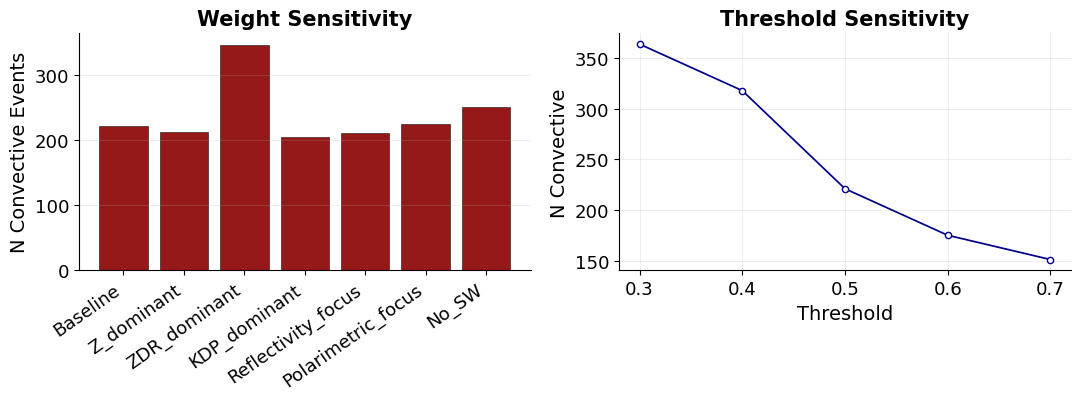

In [8]:
COMPONENT_DIR = DERIVED_DIR / "convective_components_202606"
SCORES = ["prob_reflectivity", "prob_zdr_column", "prob_kdp", "prob_doppler"]

component_files = sorted(COMPONENT_DIR.glob("*.nc"))
if not component_files:
    print(f"No criterion-score files in {COMPONENT_DIR}; run criterion_scores_all_files() first.")
else:
    components = xr.open_mfdataset(component_files, combine="nested", concat_dim="time")
    box = ((abs(components.x_utm - RADIOMETER_XY[0]) <= GRID_HALF_WIDTH)
           & (abs(components.y_utm - RADIOMETER_XY[1]) <= GRID_HALF_WIDTH))
    components = components.where(box, drop=True)[SCORES]
    warm_events = pd.read_csv(PROCESSED_DIR / "filtered_events_with_conv_index.csv", parse_dates=["start", "end"])
    print(f"{components.time.size} radar time steps, {len(warm_events)} warm-season events")

    weight_results, categories = sensitivity.run_weight_sensitivity(components, warm_events)
    threshold_results = sensitivity.run_threshold_sensitivity(components, warm_events)
    stability = sensitivity.stability_metrics(weight_results)
    print(weight_results[["name", "n_convective", "pct_convective"]].to_string(index=False))
    print(f"\nAgreement of all weight sets: {sensitivity.classification_agreement(categories):.1f} %")
    print(stability.to_string(index=False))
    print(threshold_results.to_string(index=False))

    fig, axes = sensitivity.plot_sensitivity(weight_results, threshold_results)
    fig.savefig(FIG_DIR / "fA01.png", dpi=300, bbox_inches="tight")
    plt.show()

## 7. Example event: Z_h and Z_DR above the radiometer with the −5 °C isotherm

Height–time sections of the gridded Z_h and Z_DR averaged over the grid points within ± 100 m of the radiometer; only gates with Z_h > 0 dBZ (radar echo) are coloured. Black line: −5 °C isotherm from the MWR profile (solid where the profile is measured, dashed where it is flagged; grey band: vertical grid cell of the profile; no line where the radiometer gives no profile, e.g. during rain). Dotted line: 0 °C level (bottom of the melting layer in Section 4). Vertical line: rain onset; shading: onset ± 30 min used for the convective probability. The bottom panel shows the convective and hail probability (P95 over the grid) of each time step.

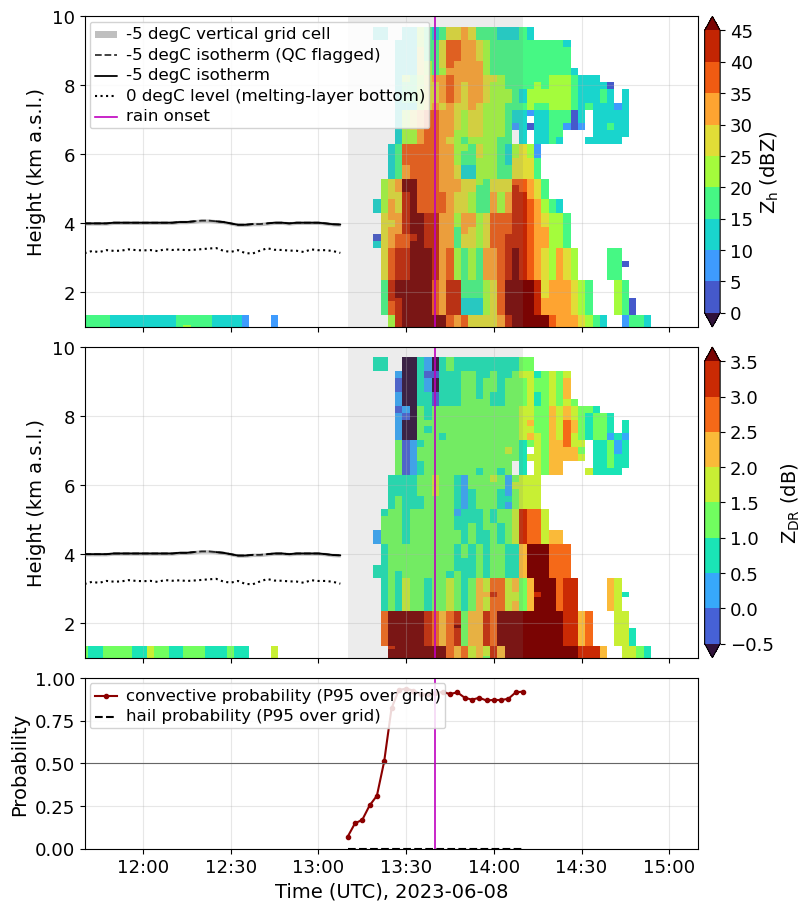

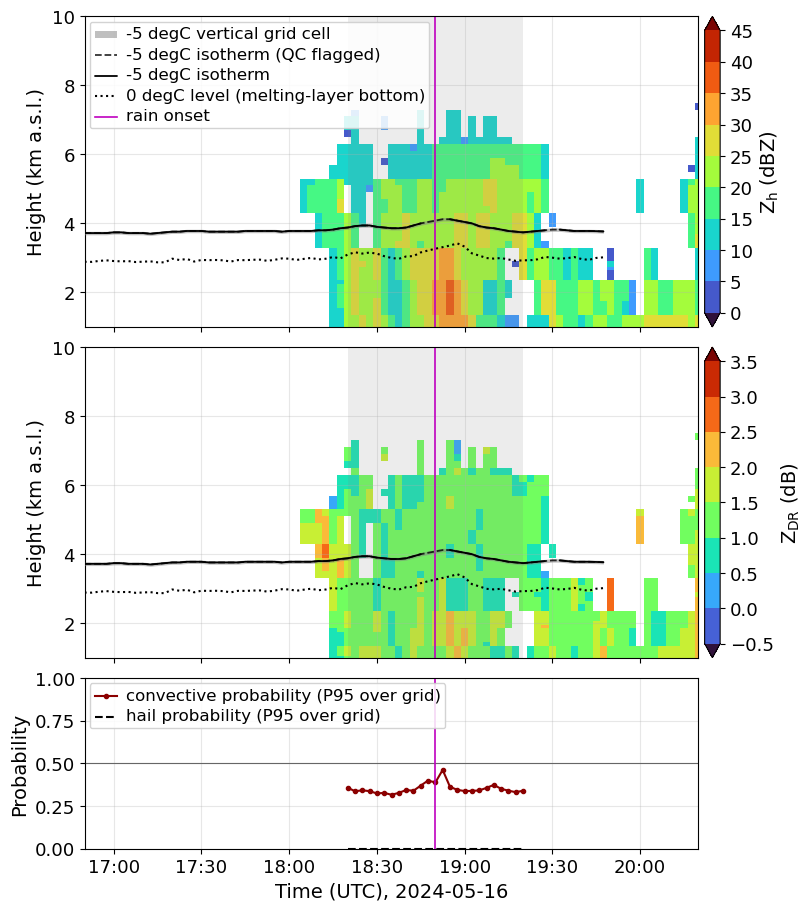

In [9]:
def plot_example_event(onset, radar_ds, minus5_ds, fl_0c, result, out_file=None):
    """Z_h and Z_DR above the radiometer with the -5 degC isotherm, and the convective probability."""
    t_onset = np.datetime64(onset)
    column = radar_ds.where((abs(radar_ds.x_utm - RADIOMETER_XY[0]) <= 100)
                            & (abs(radar_ds.y_utm - RADIOMETER_XY[1]) <= 100), drop=True).mean(["x_utm", "y_utm"])
    t0, t1 = column.time.values[0], column.time.values[-1]
    isotherm = minus5_ds.sel(time=slice(t0, t1))

    fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1, 0.55]}, constrained_layout=True)
    panels = [("Z_h_corr", "Z$_\\mathrm{h}$ (dBZ)", np.arange(0, 50, 5)),
              ("zdr_corr", "Z$_\\mathrm{DR}$ (dB)", np.arange(-0.5, 3.6, 0.5))]
    echo = column["Z_h_corr"] > 0                       # radar echo (as for the echo top); clear air stays white
    for ax, (var, label, levels) in zip(axes[:2], panels):
        column[var].where(echo).plot(ax=ax, x="time", y="h_msl_m", cmap="turbo", levels=levels, extend="both",
                         cbar_kwargs={"label": label, "pad": 0.01})
        plot_minus5_isotherm(ax, isotherm, show_label=True)
        fl = fl_0c.sel(time=slice(t0, t1))
        ax.plot(fl.time, fl, ls=":", c="k", lw=1.5, label="0 degC level (melting-layer bottom)")
        ax.axvline(t_onset, c="m", lw=1.2, label="rain onset")
        ax.axvspan(t_onset - PROB_HALF_WINDOW, t_onset + PROB_HALF_WINDOW, color="0.5", alpha=0.15, lw=0)
        ax.set_ylim(1000, 10000)
        ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:g}")
        ax.set_ylabel("Height (km a.s.l.)")
        ax.set_xlabel("")
        ax.set_title("")
        ax.grid(alpha=0.3)
    axes[0].legend(loc="upper left", fontsize=8, framealpha=0.85)

    q95 = result["convective_probability"].quantile(0.95, dim=["x_utm", "y_utm"])
    hail = result["hail_probability"].quantile(0.95, dim=["x_utm", "y_utm"])
    axes[2].plot(q95.time, q95, c="darkred", marker="o", ms=3, label="convective probability (P95 over grid)")
    axes[2].plot(hail.time, hail, c="k", ls="--", label="hail probability (P95 over grid)")
    axes[2].axhline(0.5, c="0.4", lw=0.8)
    axes[2].axvline(t_onset, c="m", lw=1.2)
    axes[2].set_ylim(0, 1)
    axes[2].set_ylabel("Probability")
    axes[2].legend(loc="upper left", fontsize=8, framealpha=0.85)
    axes[2].grid(alpha=0.3)
    axes[2].set_xlim(t0, t1)
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[2].set_xlabel(f"Time (UTC), {str(onset)[:10]}")
    style_fonts(fig)                 # common font family and sizes (src/figure_style.py)
    if out_file:
        fig.savefig(out_file, dpi=300, bbox_inches="tight")
    plt.show()


for onset in EXAMPLES:
    plot_example_event(onset, radar[onset], minus5[onset], zero_deg[onset], prob[onset],
                       out_file=FIG_DIR / "examples" / f"example_event_{pd.Timestamp(onset):%Y%m%d_%H%M}.png")